In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
train_df = pd.read_csv("../data/training.csv")
test_df = pd.read_csv("../data/testing.csv")

In [52]:
train_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [53]:
train_df["Churn"].value_counts()

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

In [54]:
train_df["Churn"].value_counts(normalize=True) * 100

Churn
1.0    56.71072
0.0    43.28928
Name: proportion, dtype: float64

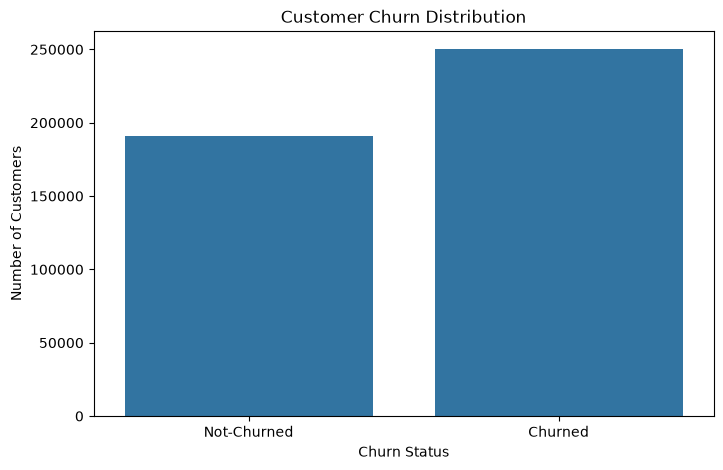

In [55]:
plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.xticks([0, 1], ["Not-Churned", "Churned"])

plt.show()

In [56]:
numerical_columns = train_df.select_dtypes(include=["int64", "float64"]).columns

print(numerical_columns)

Index(['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='str')


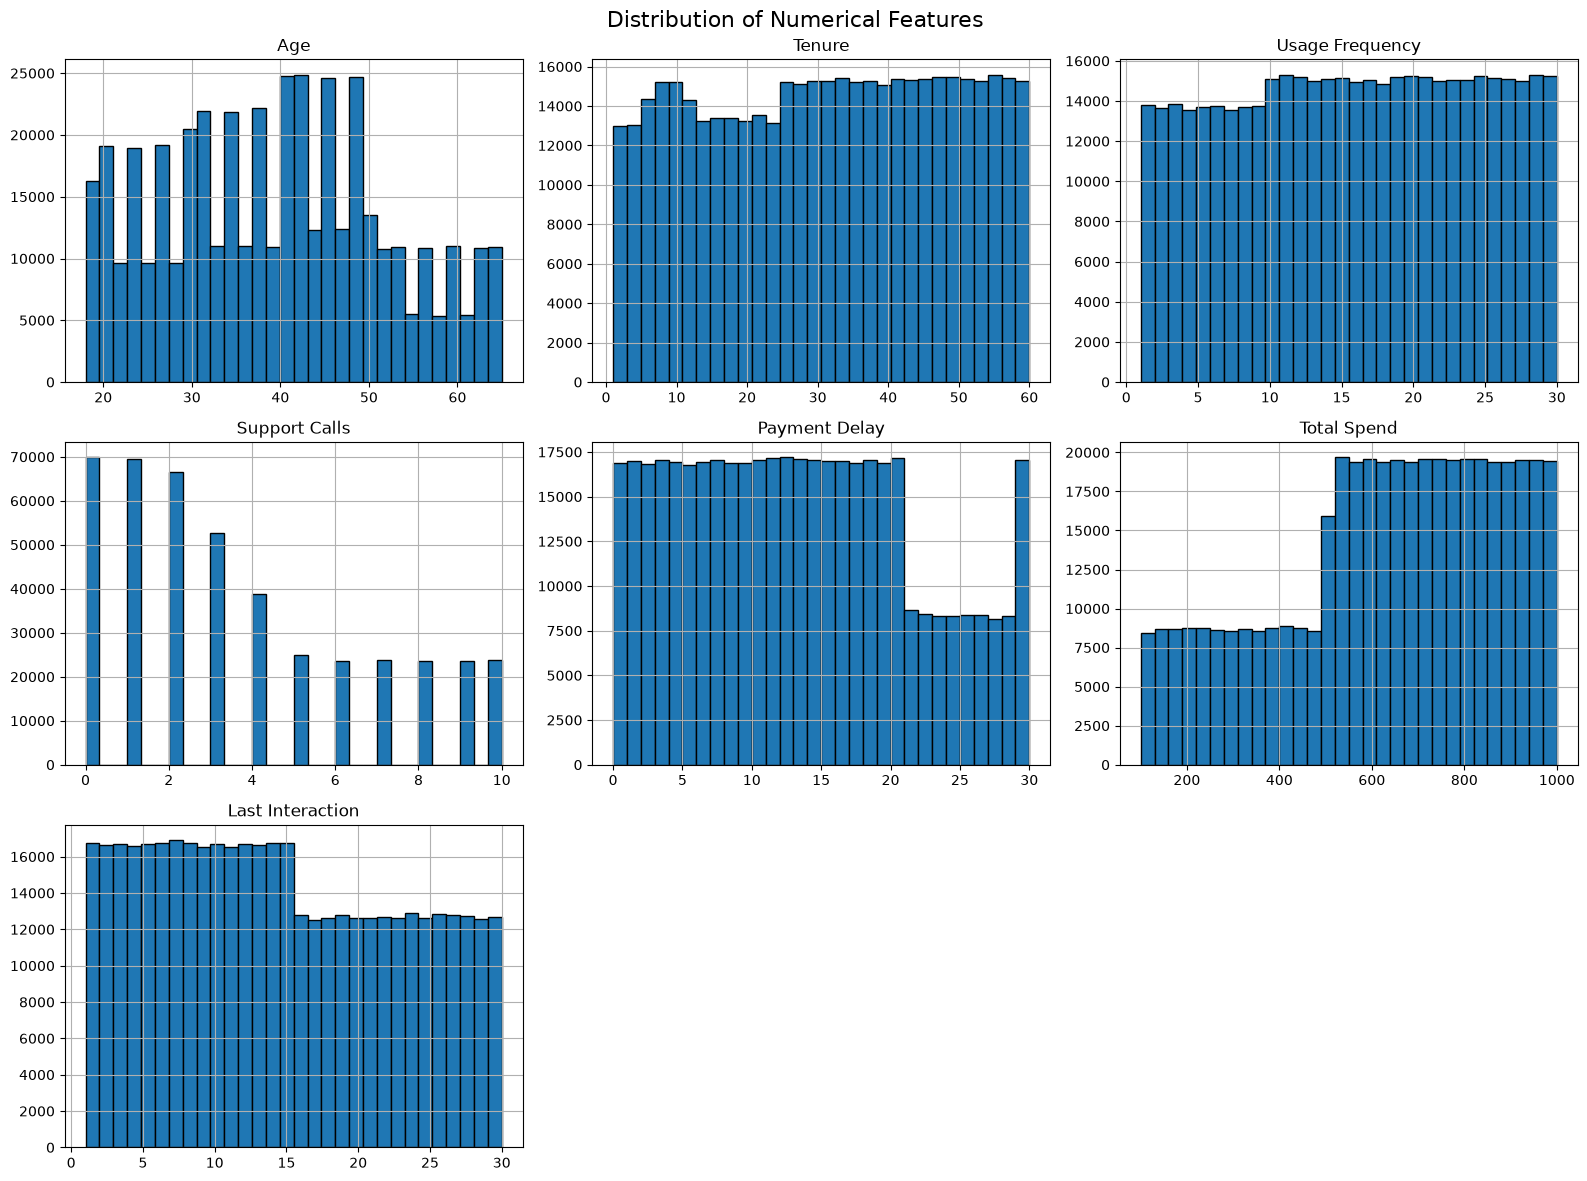

In [57]:
numerical_features = [
    col for col in numerical_columns
    if col not in ["CustomerID", "Churn"]
]

train_df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

In [58]:
categorical_columns = train_df.select_dtypes(
    include=["str", "category"]
).columns

print(categorical_columns)

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='str')


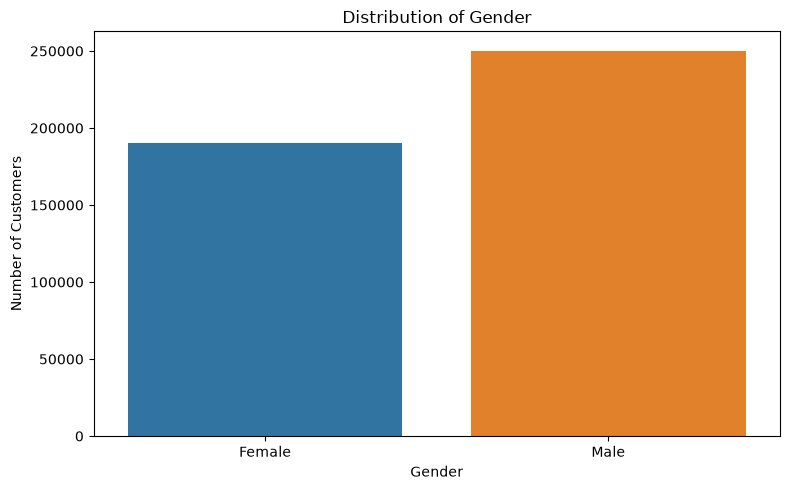

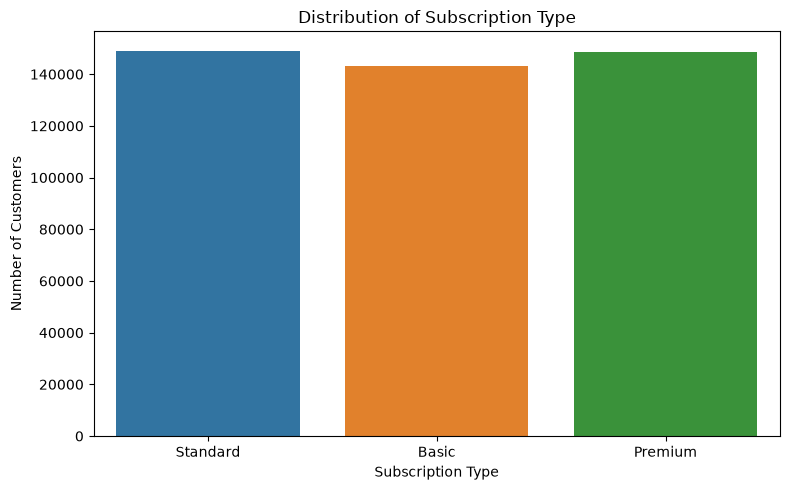

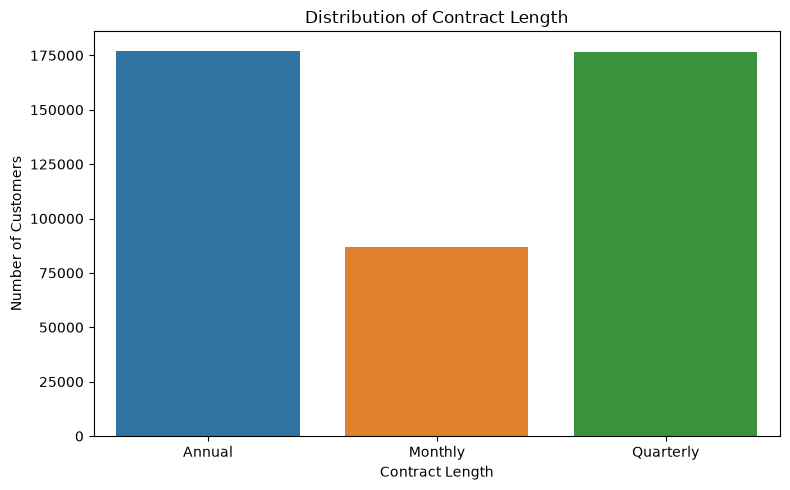

In [59]:
for col in categorical_columns:

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=train_df,
        x=col,
        hue=col,
        legend=False
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()

Bellow will check how various attribut contribut and affect the customer churn

number of customer churn or not churn  for each contract type

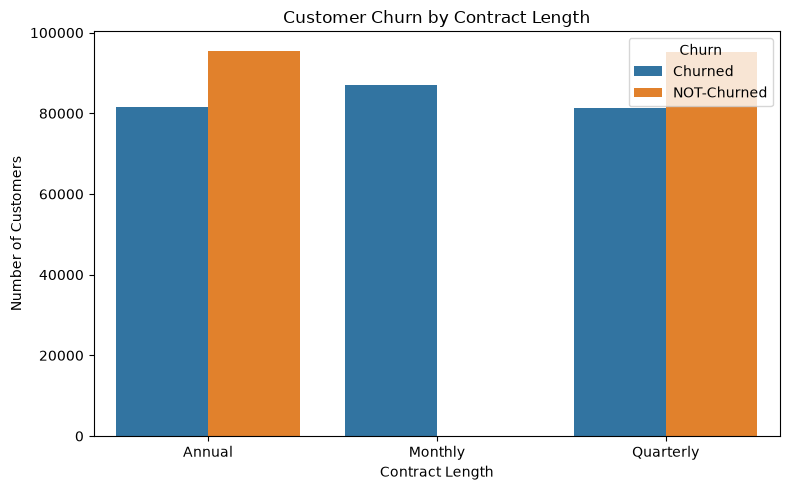

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Contract Length",
    hue="Churn",
    hue_order=[1,0]
)

plt.title("Customer Churn by Contract Length")
plt.xlabel("Contract Length")
plt.ylabel("Number of Customers")
plt.legend(title="Churn", labels=["Churned", "NOT-Churned"])

plt.tight_layout()
plt.show()

percentage of customer churn or not churn  for each contract type

In [61]:
churn_percentage = pd.crosstab(
    train_df["Contract Length"],
    train_df["Churn"],
    normalize="index"
) * 100

print(churn_percentage)

Churn                  0.0         1.0
Contract Length                       
Annual           53.923859   46.076141
Monthly           0.000000  100.000000
Quarterly        53.974395   46.025605


above percentage shows that monthly contract have an 100% churn rate

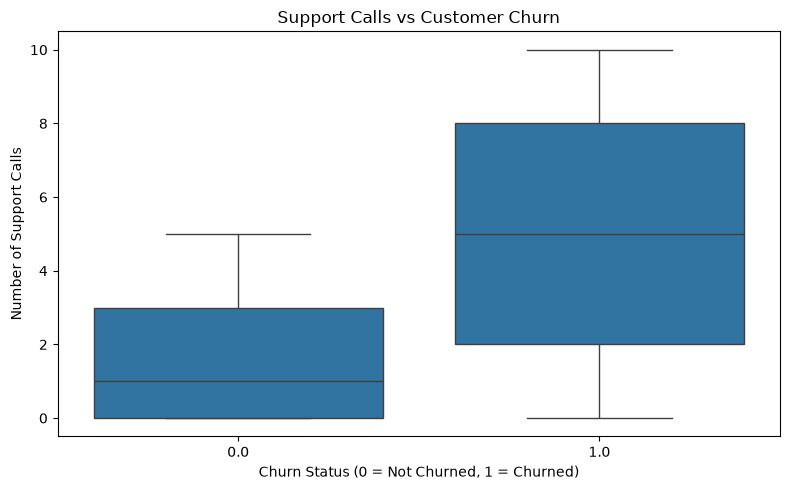

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Support Calls"
)

plt.title("Support Calls vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Number of Support Calls")

plt.tight_layout()
plt.show()

Above graph shows that The customer churned have more median support calls that is and the customer not churned  have median support calls of 
2 and 3 support calls overlap for both churned and not churned 

highest calls for not churned is 5 
lowest calls for not churned is 0

highest calls for churned customer is 10
lowest calls for churned customer is 0

In [63]:
train_df.groupby("Churn")["Support Calls"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,1.586418,1.289975,0.0,0.0,1.0,3.0,5.0
1.0,249999.0,5.144861,3.141639,0.0,2.0,5.0,8.0,10.0


Relation of payment delay and customer churn

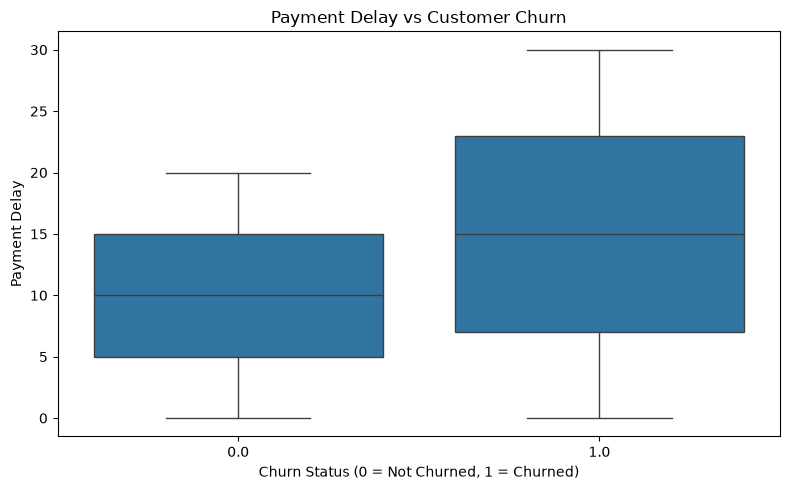

In [64]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Payment Delay"
)

plt.title("Payment Delay vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Payment Delay")

plt.tight_layout()
plt.show()

In [65]:
train_df.groupby("Churn")["Payment Delay"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,10.015500,6.056744,0.0,5.0,10.0,15.0,20.0
1.0,249999.0,15.217729,8.974081,0.0,7.0,15.0,23.0,30.0


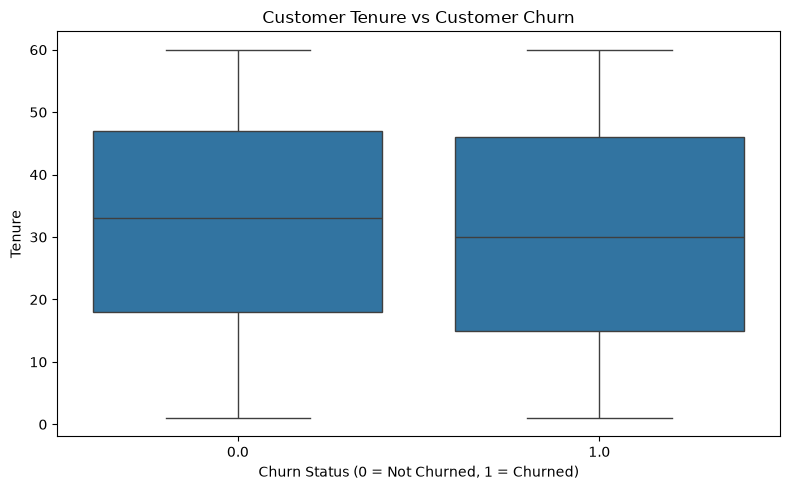

In [66]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Tenure"
)

plt.title("Customer Tenure vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Tenure")

plt.tight_layout()
plt.show()

The descriptive statistics indicate that tenure has relatively similar distributions among churned and non-churned customers. The difference in their mean and median values is small, suggesting that tenure may have a weaker individual association with churn

In [67]:
train_df.groupby("Churn")["Tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,32.281754,17.089172,1.0,18.0,33.0,47.0,60.0
1.0,249999.0,30.473598,17.341065,1.0,15.0,30.0,46.0,60.0


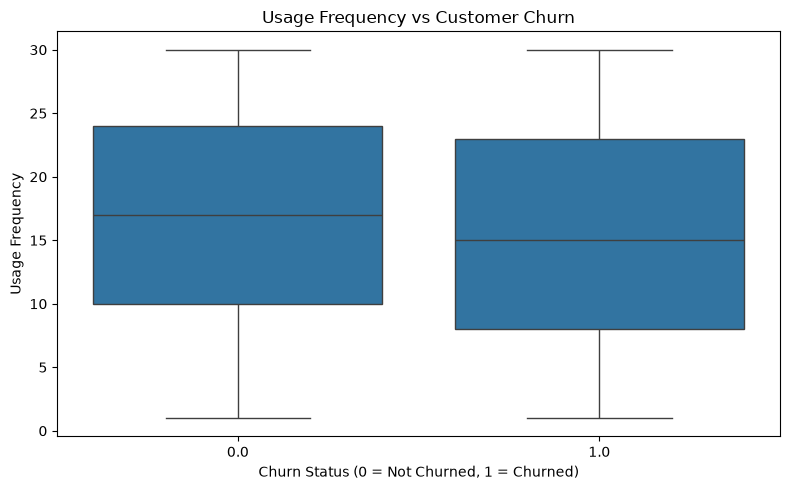

In [68]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Usage Frequency"
)

plt.title("Usage Frequency vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Usage Frequency")

plt.tight_layout()
plt.show()

The descriptive statistics show that usage frequency is relatively similar between churned and non-churned customers. Although churned customers have a slightly lower average usage frequency, the difference is small.

In [69]:
train_df.groupby("Churn")["Usage Frequency"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,16.260552,8.446843,1.0,10.0,17.0,24.0,30.0
1.0,249999.0,15.461658,8.675252,1.0,8.0,15.0,23.0,30.0


In [70]:
train_df["Tenure Group"] = pd.cut(
    train_df["Tenure"],
    bins=[0, 20, 40, 60],
    labels=["Low", "Medium", "High"]
)

train_df["Usage Group"] = pd.cut(
    train_df["Usage Frequency"],
    bins=[0, 10, 20, 30],
    labels=["Low", "Medium", "High"]
)

to create a new data frame in order not to change the main train_df but i already changed (added new colums tenure grup and usage group)

In [71]:
analysis_df = train_df.copy()

In [72]:
analysis_df["Tenure Group"] = pd.cut(
    analysis_df["Tenure"],
    bins=[0, 20, 40, 60],
    labels=["Low", "Medium", "High"]
)

analysis_df["Usage Group"] = pd.cut(
    analysis_df["Usage Frequency"],
    bins=[0, 10, 20, 30],
    labels=["Low", "Medium", "High"]
)

In [73]:
combined_analysis = pd.pivot_table(
    analysis_df,
    index="Tenure Group",
    columns="Usage Group",
    values="Churn",
    aggfunc="mean"
) * 100

print(combined_analysis)

Usage Group         Low     Medium       High
Tenure Group                                 
Low           70.281592  56.317498  56.648671
Medium        59.495292  53.961068  54.104448
High          54.091291  54.284488  54.284546


Combined Effect of Tenure and Usage Frequency:

The combined analysis reveals that customers with low tenure and low usage frequency have the highest observed churn rate (70.28%). Furthermore, among customers with low tenure, those with higher usage frequency exhibit a lower churn rate. This suggests that the relationship between usage frequency and customer churn may vary depending on customer tenure. 
The effect can be seen from bellow heat map

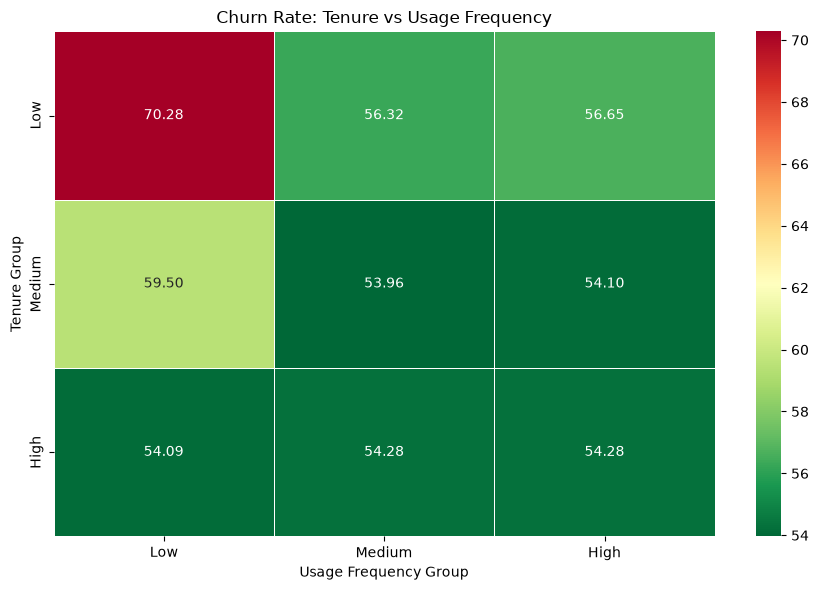

In [74]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    combined_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Tenure vs Usage Frequency")
plt.xlabel("Usage Frequency Group")
plt.ylabel("Tenure Group")

plt.tight_layout()
plt.show()

In [75]:
customer_counts = pd.crosstab(
    analysis_df["Tenure Group"],
    analysis_df["Usage Group"]
)

print(customer_counts)

Usage Group     Low  Medium   High
Tenure Group                      
Low           40342   48983  49085
Medium        46839   50807  50896
High          51243   51278  51359


In [76]:
train_df.groupby("Churn")["Total Spend"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,749.953111,144.222792,500.0,625.3,749.98,874.74,1000.0
1.0,249999.0,541.285528,259.850723,100.0,316.0,534.00,767.00,1000.0


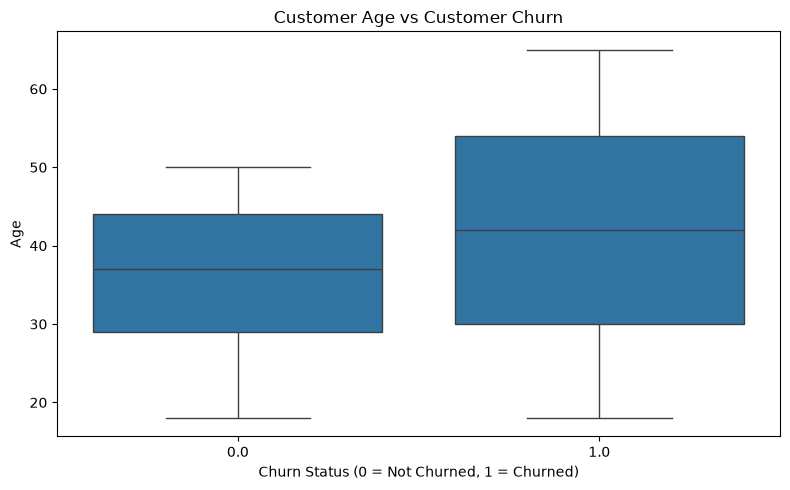

In [77]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Age"
)

plt.title("Customer Age vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

In [78]:
train_df.groupby("Churn")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,36.262973,9.203910,18.0,29.0,37.0,44.0,50.0
1.0,249999.0,41.747263,13.975085,18.0,30.0,42.0,54.0,65.0


Customer age also slightly high who tend to churn

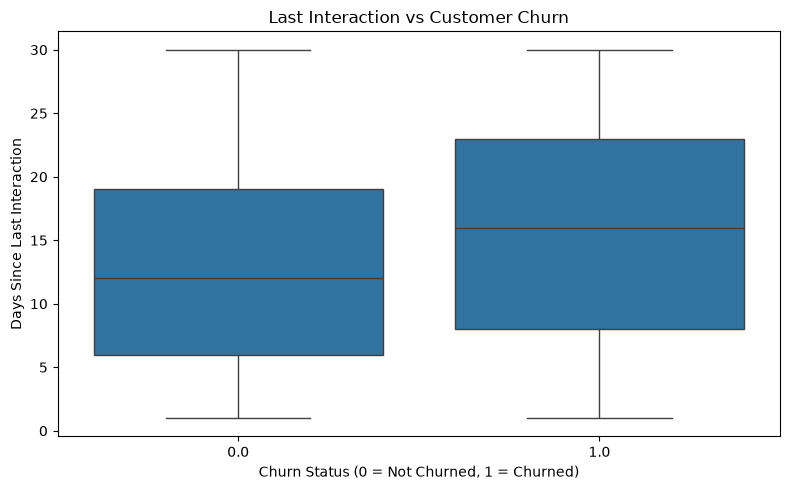

In [79]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="Last Interaction"
)

plt.title("Last Interaction vs Customer Churn")
plt.xlabel("Churn Status (0 = Not Churned, 1 = Churned)")
plt.ylabel("Days Since Last Interaction")

plt.tight_layout()
plt.show()

The descriptive analysis indicates that churned customers generally have a longer period since their last interaction than retained customers. The mean value is 15.60 days for churned customers compared with 13.01 days for non-churned customers. This suggests a moderate association between customer inactivity and churn

In [80]:
train_df.groupby("Churn")["Last Interaction"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0.0,190833.0,13.008804,8.291378,1.0,6.0,12.0,19.0,30.0
1.0,249999.0,15.604546,8.654930,1.0,8.0,16.0,23.0,30.0


In [81]:
gender_analysis = pd.crosstab(
    train_df["Gender"],
    train_df["Churn"],
    normalize="index"
) * 100

print(gender_analysis)

Churn         0.0        1.0
Gender                      
Female  33.330885  66.669115
Male    50.873120  49.126880


Gender and Customer Churn: The categorical analysis indicates a noticeable difference in churn rates across gender categories. Female customers exhibit a churn rate of approximately 66.67%, compared with 49.13% among male customers. This suggests that gender may contain predictive information for customer churn in this dataset.

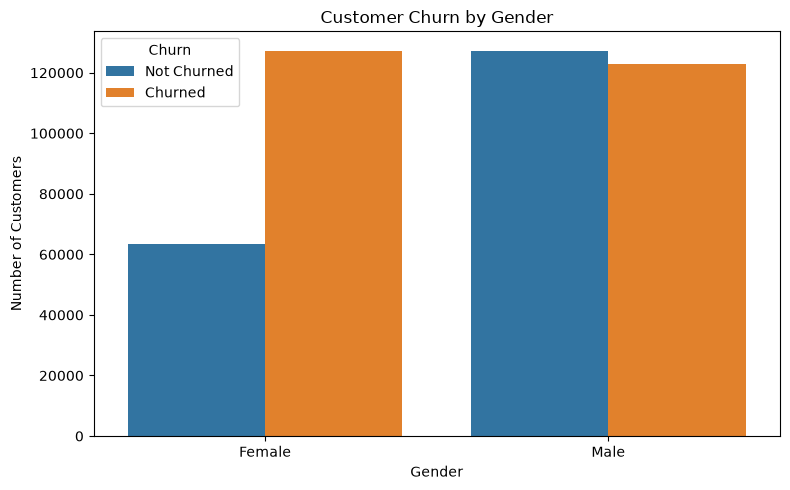

In [82]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Gender",
    hue="Churn",
    hue_order=[0, 1]
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.legend(
    title="Churn",
    labels=["Not Churned", "Churned"]
)

plt.tight_layout()
plt.show()

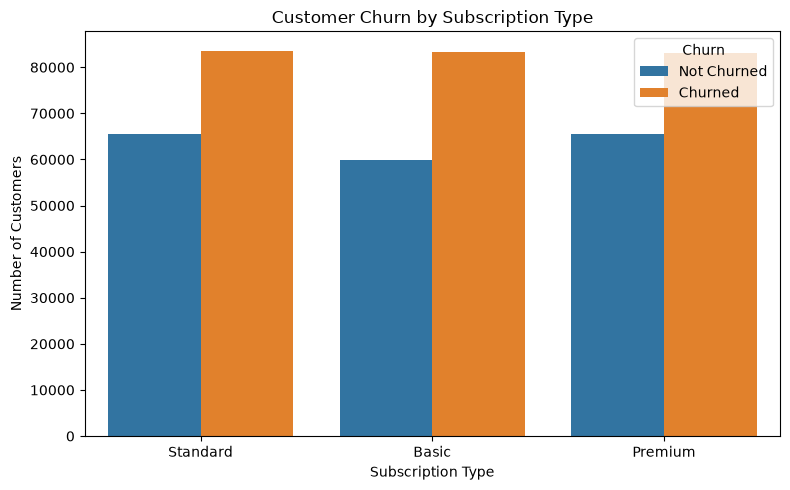

In [83]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Subscription Type",
    hue="Churn",
    hue_order=[0, 1]
)

plt.title("Customer Churn by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")

plt.legend(
    title="Churn",
    labels=["Not Churned", "Churned"]
)

plt.tight_layout()
plt.show()

The analysis indicates that churn rates are relatively similar across Basic, Standard and Premium subscription categories. Basic subscribers exhibit a churn rate of 58.18%, while Premium and Standard subscribers show churn rates of 55.94% and 56.07%, respectively. This suggests that subscription type has a relatively weak individual association with customer churn.

In [84]:
subscription_analysis = pd.crosstab(
    train_df["Subscription Type"],
    train_df["Churn"],
    normalize="index"
) * 100

print(subscription_analysis)

Churn                    0.0        1.0
Subscription Type                      
Basic              41.821767  58.178233
Premium            44.058300  55.941700
Standard           43.930047  56.069953


In [85]:
analysis_df = train_df.copy()

analysis_df["Support Group"] = pd.cut(
    analysis_df["Support Calls"],
    bins=[-1, 3, 6, 10],
    labels=["Low", "Medium", "High"]
)

analysis_df["Payment Delay Group"] = pd.cut(
    analysis_df["Payment Delay"],
    bins=[-1, 10, 20, 30],
    labels=["Low", "Medium", "High"]
)

In [86]:
support_payment_analysis = pd.pivot_table(
    analysis_df,
    index="Support Group",
    columns="Payment Delay Group",
    values="Churn",
    aggfunc="mean",
    observed=False
) * 100

print(support_payment_analysis)

Payment Delay Group         Low      Medium   High
Support Group                                     
Low                   23.937229   23.970522  100.0
Medium                73.137436   72.825593  100.0
High                 100.000000  100.000000  100.0


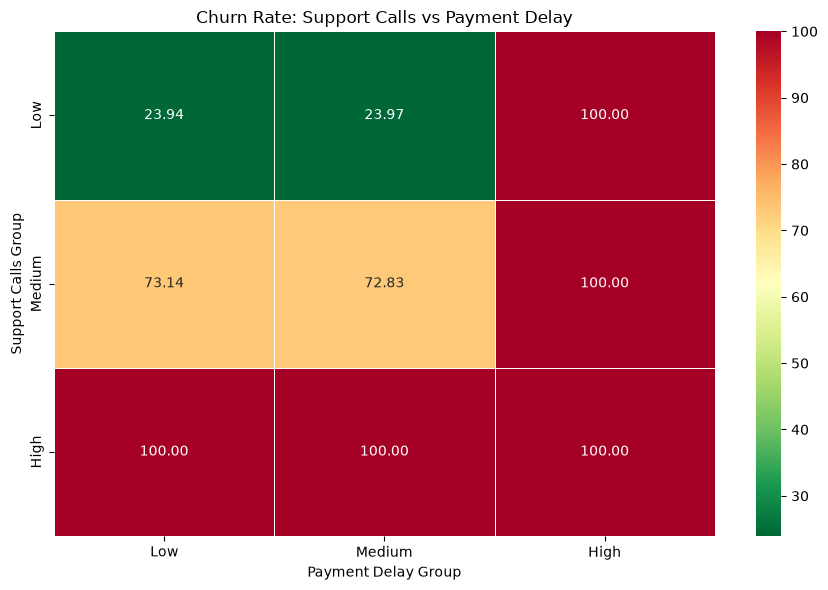

In [87]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    support_payment_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Support Calls vs Payment Delay")
plt.xlabel("Payment Delay Group")
plt.ylabel("Support Calls Group")

plt.tight_layout()
plt.show()

In [88]:
support_payment_counts = pd.crosstab(
    analysis_df["Support Group"],
    analysis_df["Payment Delay Group"]
)

print(support_payment_counts)


Payment Delay Group     Low  Medium   High
Support Group                             
Low                  119099  108963  30589
Medium                33623   30790  22809
High                  33525   30802  30632


In [89]:
print(support_payment_analysis)

Payment Delay Group         Low      Medium   High
Support Group                                     
Low                   23.937229   23.970522  100.0
Medium                73.137436   72.825593  100.0
High                 100.000000  100.000000  100.0


In [90]:
verification = pd.crosstab(
    [analysis_df["Support Group"], analysis_df["Payment Delay Group"]],
    analysis_df["Churn"]
)

print(verification)

Churn                                0.0    1.0
Support Group Payment Delay Group              
Low           Low                  90590  28509
              Medium               82844  26119
              High                     0  30589
Medium        Low                   9032  24591
              Medium                8367  22423
              High                     0  22809
High          Low                      0  33525
              Medium                   0  30802
              High                     0  30632



Support Calls + Payment Delay
Our combined analysis revealed:
    • Customers with 7–10 support calls had a 100% observed churn rate.
    • Customers with payment delays of 21–30 had a 100% observed churn rate.
    • Customers with 4–6 support calls had approximately 73% churn for low and medium payment delays.
Customers with 0–3 support calls had approximately 24% churn for low and medium payment delays.

In [91]:
analysis_df["Spend Group"] = pd.cut(
    analysis_df["Total Spend"],
    bins=[0, 400, 700, 1000],
    labels=["Low", "Medium", "High"]
)

analysis_df["Payment Delay Group"] = pd.cut(
    analysis_df["Payment Delay"],
    bins=[-1, 10, 20, 30],
    labels=["Low", "Medium", "High"]
)
spend_payment_analysis = pd.pivot_table(
    analysis_df,
    index="Spend Group",
    columns="Payment Delay Group",
    values="Churn",
    aggfunc="mean",
    observed=False
) * 100

print(spend_payment_analysis)

Payment Delay Group         Low      Medium   High
Spend Group                                       
Low                  100.000000  100.000000  100.0
Medium                41.927992   41.380471  100.0
High                  31.242534   31.580463  100.0


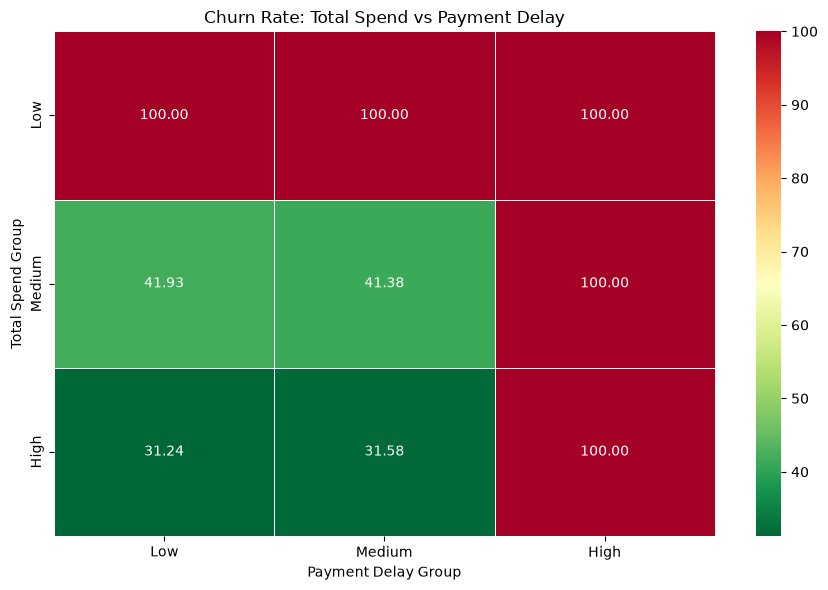

In [92]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    spend_payment_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Total Spend vs Payment Delay")
plt.xlabel("Payment Delay Group")
plt.ylabel("Total Spend Group")

plt.tight_layout()
plt.show()

In [93]:
spend_payment_counts = pd.crosstab(
    analysis_df["Spend Group"],
    analysis_df["Payment Delay Group"]
)

print(spend_payment_counts)

Payment Delay Group    Low  Medium   High
Spend Group                              
Low                  30718   28306  27830
Medium               68465   62399  28233
High                 87064   79850  27967


Total Spend and Payment Delay: The combined analysis indicates that customers with low total spending exhibit a 100% observed churn rate across all payment-delay categories. Among medium- and high-spending customers, high payment delays are associated with a 100% churn rate. This suggests that both spending behavior and payment delays contain useful information about customer churn.

In [94]:
print(spend_payment_analysis)

Payment Delay Group         Low      Medium   High
Spend Group                                       
Low                  100.000000  100.000000  100.0
Medium                41.927992   41.380471  100.0
High                  31.242534   31.580463  100.0


In [95]:
analysis_df["Support Group"] = pd.cut(
    analysis_df["Support Calls"],
    bins=[-1, 3, 6, 10],
    labels=["Low", "Medium", "High"]
)

analysis_df["Tenure Group"] = pd.cut(
    analysis_df["Tenure"],
    bins=[0, 20, 40, 60],
    labels=["Low", "Medium", "High"]
)
tenure_support_analysis = pd.pivot_table(
    analysis_df,
    index="Tenure Group",
    columns="Support Group",
    values="Churn",
    aggfunc="mean",
    observed=False
) * 100

print(tenure_support_analysis)

Support Group        Low     Medium   High
Tenure Group                              
Low            36.637044  82.032898  100.0
Medium         32.220825  79.633021  100.0
High           30.510865  78.569274  100.0


Tenure and Support Calls: The combined analysis reveals that customers with high support-call frequency exhibit a 100% observed churn rate across all tenure categories. Customers with medium support-call frequency show churn rates of approximately 79–82%, while those with low support-call frequency exhibit substantially lower churn rates. This indicates that support-call frequency has a stronger observed association with churn than tenure in these combinations.

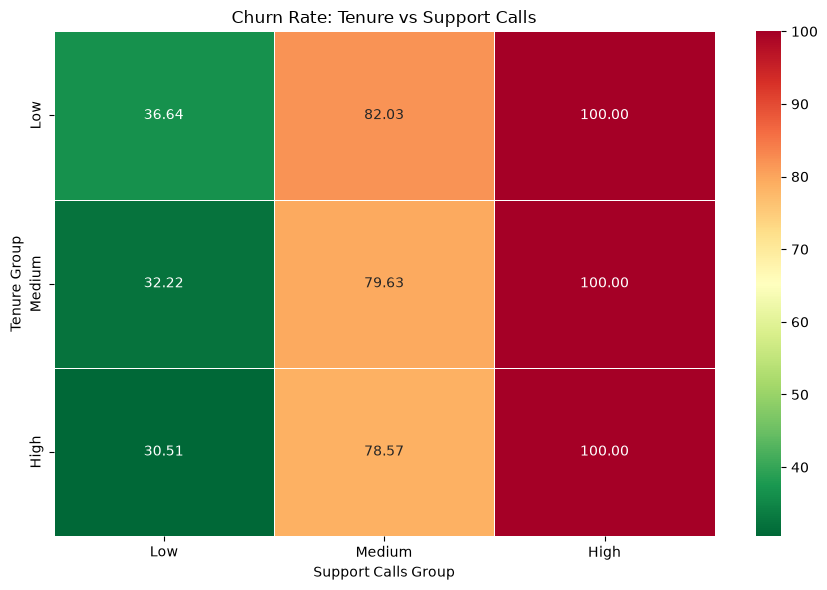

In [96]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    tenure_support_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Tenure vs Support Calls")
plt.xlabel("Support Calls Group")
plt.ylabel("Tenure Group")

plt.tight_layout()
plt.show()

In [97]:
analysis_df["Age Group"] = pd.cut(
    analysis_df["Age"],
    bins=[17, 30, 45, 65],
    labels=["Young", "Middle-aged", "Older"]
)

analysis_df["Spend Group"] = pd.cut(
    analysis_df["Total Spend"],
    bins=[0, 400, 700, 1000],
    labels=["Low", "Medium", "High"]
)
age_spend_analysis = pd.pivot_table(
    analysis_df,
    index="Age Group",
    columns="Spend Group",
    values="Churn",
    aggfunc="mean",
    observed=False
) * 100

print(age_spend_analysis)

Spend Group    Low     Medium       High
Age Group                               
Young        100.0  49.880888  39.476168
Middle-aged  100.0  39.309775  28.914898
Older        100.0  70.047745  60.404494


Age and Total Spend: The combined analysis indicates that customers with low total spending exhibit a 100% observed churn rate across all age groups. Among medium- and high-spending customers, older customers exhibit comparatively higher churn rates than younger and middle-aged customers. This suggests that the relationship between spending behaviour and churn may vary across age groups.

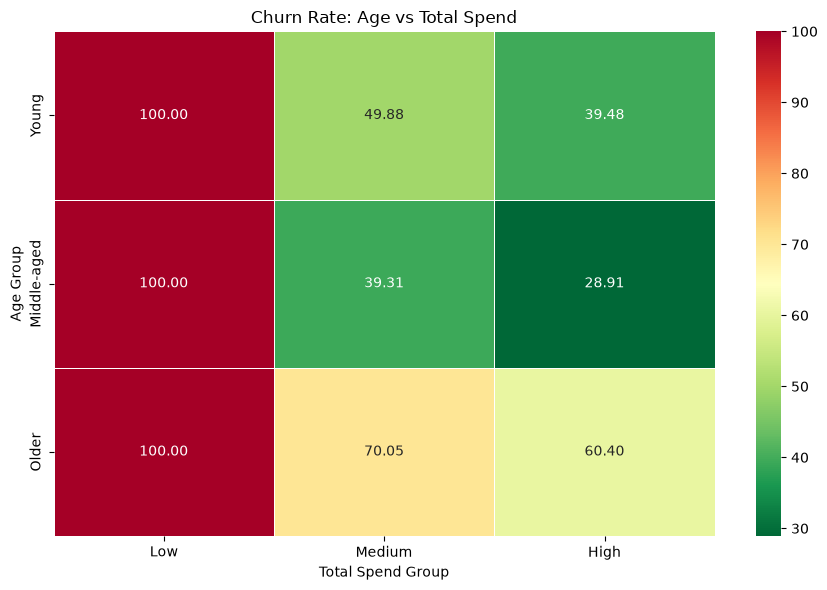

In [98]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    age_spend_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Age vs Total Spend")
plt.xlabel("Total Spend Group")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

In [99]:
analysis_df["Usage Group"] = pd.cut(
    analysis_df["Usage Frequency"],
    bins=[0, 10, 20, 30],
    labels=["Low", "Medium", "High"]
)
usage_payment_analysis = pd.pivot_table(
    analysis_df,
    index="Usage Group",
    columns="Payment Delay Group",
    values="Churn",
    aggfunc="mean",
    observed=False
) * 100

print(usage_payment_analysis)

Payment Delay Group        Low     Medium   High
Usage Group                                     
Low                  50.612309  50.704785  100.0
Medium               44.619075  44.495592  100.0
High                 44.732393  44.789312  100.0


High payment delay: Every usage group has a 100% churn rate when payment delay is high (21–30 days).



Low usage: Customers with low usage have approximately 50.6% churn, regardless of whether payment delay is low or medium.



Medium and high usage: These groups have similar churn rates of approximately 44.5–44.8% under low and medium payment delays.



Payment delay appears more strongly associated with churn than usage frequency in this comparison.

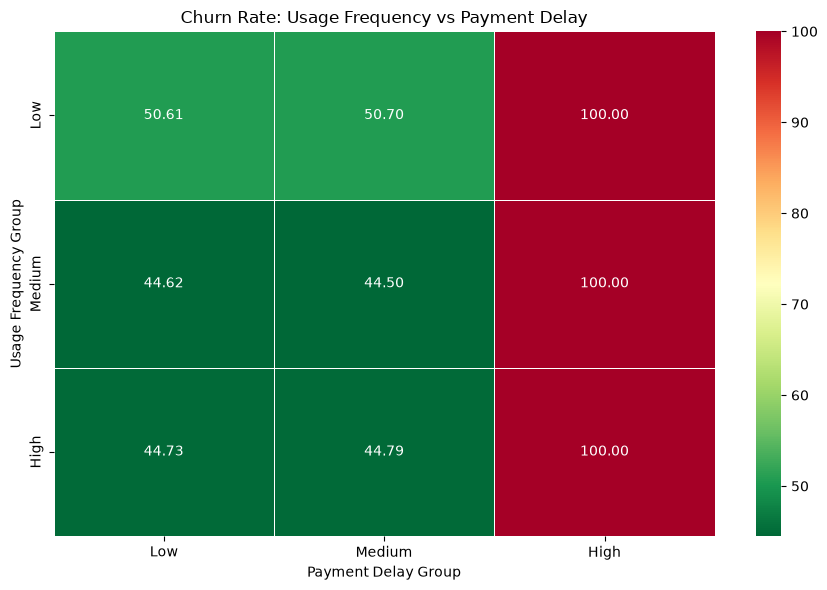

In [100]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    usage_payment_analysis,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5
)

plt.title("Churn Rate: Usage Frequency vs Payment Delay")
plt.xlabel("Payment Delay Group")
plt.ylabel("Usage Frequency Group")

plt.tight_layout()
plt.show()